# 01 · Exploratory data analysis — M5 Walmart subset

**Goal.** Understand the demand we must forecast *before* choosing models, features and
inventory rules. Each section answers one question and ends with what it means for the
modelling.

| § | Question |
|---|---|
| 1 | How does total demand evolve over time? |
| 2 | How are daily sales distributed, and how concentrated are they? |
| 3 | How often does an item sell nothing on a given day? |
| 4 | Which demand patterns occur (ADI / CV² classification)? |
| 5 | How strong is weekly seasonality? |
| 6 | Is there yearly seasonality? |
| 7 | Do prices move sales (price-elasticity hints)? |
| 8 | Do events and SNAP days move sales? |
| 9 | How do stores and categories compare? |

**Data.** The validated table written by `make data` (`data/processed/sales.parquet`):
one row per SKU-store-day with units sold (`y`), price and calendar fields. Key figures
are saved to `docs/figures/` (PNG, 150 dpi) for the report.

In [1]:
from pathlib import Path
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if Path.cwd().name == "notebooks":  # run everything relative to the repository root
    os.chdir("..")

from demand_engine.data.transform import ADI_CUT, CV2_CUT, classify_profile, demand_profile

FIG_DIR = Path("docs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
COLORS = {"FOODS": "#10b981", "HOUSEHOLD": "#6366f1", "HOBBIES": "#f59e0b"}
CLASS_COLORS = {"smooth": "#10b981", "erratic": "#0ea5e9", "intermittent": "#6366f1", "lumpy": "#f43f5e"}
WEEKDAYS = {1: "Sat", 2: "Sun", 3: "Mon", 4: "Tue", 5: "Wed", 6: "Thu", 7: "Fri"}

plt.rcParams.update({
    "figure.figsize": (10, 4), "figure.dpi": 110, "savefig.dpi": 150,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.alpha": 0.3,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "legend.frameon": False, "font.size": 10,
})


def save(fig: plt.Figure, name: str) -> None:
    """Save a figure to docs/figures as a tight PNG."""
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", facecolor="white")

In [2]:
df = pd.read_parquet("data/processed/sales.parquet")
report = json.loads(Path("data/processed/quality_report.json").read_text())
print(f"{report['n_series']:,} SKU-store series · {report['n_items']} items · {report['n_stores']} stores · "
      f"{report['start']} → {report['end']} ({report['n_days']} days) · {report['n_rows']:,} rows")

# Demand relative to the series' own average, and to its own same-weekday average.
# Ratios make series of very different volumes comparable; the weekday version removes
# weekly seasonality so that event / price / SNAP effects are not confounded with weekends.
series_mean = df.groupby("unique_id")["y"].transform("mean")
dow_mean = df.groupby(["unique_id", "wday"])["y"].transform("mean")
df["rel"] = df["y"] / series_mean.where(series_mean > 0)
df["rel_dow"] = df["y"] / dow_mean.where(dow_mean > 0)
df.head(3)

1,961 SKU-store series · 498 items · 4 stores · 2014-05-24 → 2016-05-22 (730 days) · 1,371,549 rows


,unique_id,item_id,dept_id,cat_id,store_id,state_id,ds,y,sell_price,wm_yr_wk,wday,month,year,event_name_1,event_type_1,snap,rel,rel_dow
0,FOODS_1_011_CA_1,FOODS_1_011,FOODS_1,FOODS,CA_1,CA,2014-07-02,4.0,2.48,11422,5,7,2014,none,none,1,4.732877,6.387097
1,FOODS_1_011_CA_1,FOODS_1_011,FOODS_1,FOODS,CA_1,CA,2014-07-03,5.0,2.48,11422,6,7,2014,none,none,1,5.916096,6.346154
2,FOODS_1_011_CA_1,FOODS_1_011,FOODS_1,FOODS,CA_1,CA,2014-07-04,3.0,2.48,11422,7,7,2014,IndependenceDay,National,1,3.549658,3.030612


## 1 · Total sales trend

Daily units summed over all series, with a 28-day rolling mean to show the level.

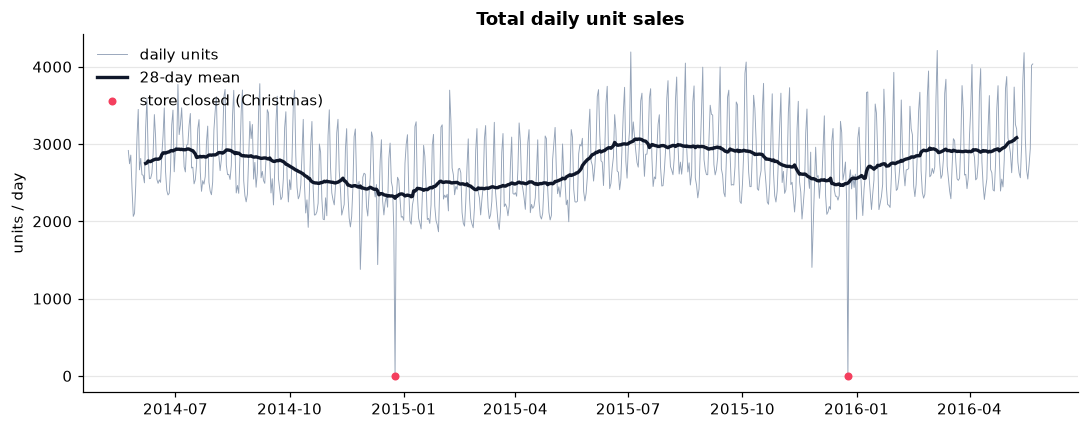

closed days: ['2014-12-25', '2015-12-25']
mean daily units: first 365 days 2,603 → last 365 days 2,854 (+9.7 % year on year)


established series (1,706): +4.5 % year on year; later-starting series supply 7.9% of last-year units


In [3]:
daily = df.groupby("ds")["y"].sum()
closed = daily[daily < 0.1 * daily.median()]
fig, ax = plt.subplots()
ax.plot(daily.index, daily, lw=0.6, color="#94a3b8", label="daily units")
ax.plot(daily.index, daily.rolling(28, center=True).mean(), lw=2.2, color="#0f172a", label="28-day mean")
ax.scatter(closed.index, closed, color="#f43f5e", zorder=3, s=18, label="store closed (Christmas)")
ax.set(title="Total daily unit sales", ylabel="units / day")
ax.legend(loc="upper left")
save(fig, "01_total_sales_trend")
plt.show()

# Like-for-like trend: each 365-day window contains every season exactly once.
first_year, last_year = daily.iloc[:365].mean(), daily.iloc[-365:].mean()
print(f"closed days: {[d.date().isoformat() for d in closed.index]}")
print(f"mean daily units: first 365 days {first_year:,.0f} → last 365 days {last_year:,.0f} "
      f"({100 * (last_year / first_year - 1):+.1f} % year on year)")

# How much of that is growth of existing items vs items that start selling later?
# (Leading zeros are trimmed, so a series "starts" at its first sale; 60 days of grace
# keeps slow sellers that merely had no sale on day 1 in the established group.)
first_sale = df.groupby("unique_id")["ds"].min()
established = first_sale[first_sale <= daily.index[0] + pd.Timedelta(days=60)].index
est = df[df["unique_id"].isin(established)].groupby("ds")["y"].sum()
last_days = df[df["ds"] > df["ds"].max() - pd.Timedelta(days=365)]
new_share = last_days.loc[~last_days["unique_id"].isin(established), "y"].sum() / last_days["y"].sum()
print(f"established series ({len(established):,}): {100 * (est.iloc[-365:].mean() / est.iloc[:365].mean() - 1):+.1f} % "
      f"year on year; later-starting series supply {new_share:.1%} of last-year units")

**Reading.** Three patterns are visible: a pronounced weekly ripple (§5), a seasonal swing
with a summer high and a winter low (§6), and growth. Comparing whole years (so the seasons
cancel), total demand rises by almost 10 %: about half of that is genuine growth of
established items (≈ +5 %), the rest comes from items that only start selling during the
period (values printed above). Stores close on Christmas Day, so sales drop to zero:
genuine zeros that a model must learn from the calendar, not missing data.

**Implication.** A growing level makes the most recent demand the most informative input
(the "origin" features of the LightGBM model) and explains why models fitted on history
tend to under-forecast slightly; calendar features handle the exceptional days.

## 2 · Sales distribution

How many units does an item sell on a day, and how unequal are the items? Left: units
sold on days with at least one sale (both axes logarithmic). Right: a concentration
(Lorenz-type) curve — series sorted from largest to smallest, against their cumulative
share of all units sold.

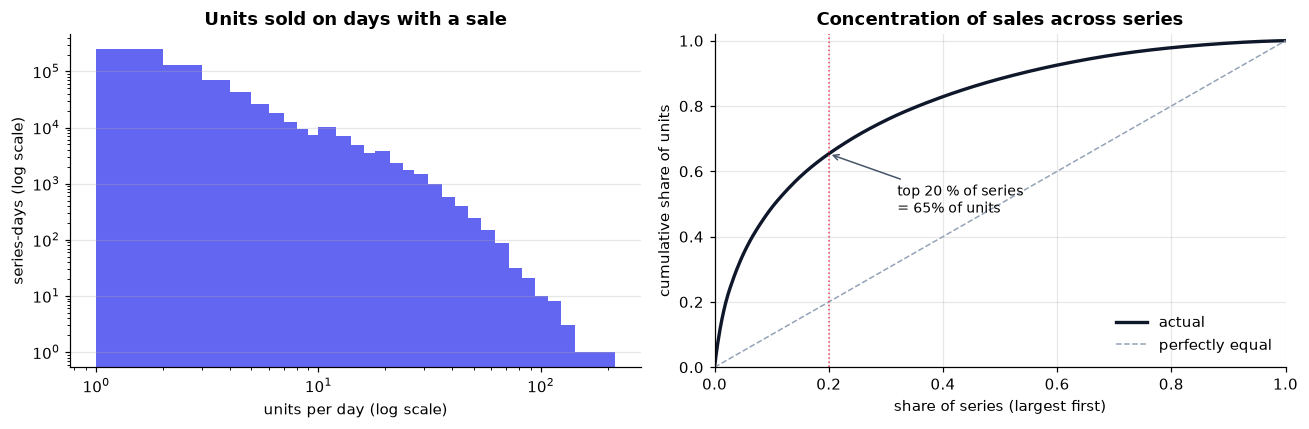

days with a sale: 43.7% of series-days
units on a selling day: median 2, 90th pct 7, 99th pct 23, max 215; share selling exactly 1 unit: 41.3%
mean units/day per series: median 0.70, 90th pct 3.20, max 22.3
top 20 % of series sell 65.4% of units; top 1 % sell 11.7%


In [4]:
pos = df.loc[df["y"] > 0, "y"]
volume = df.groupby("unique_id")["y"].sum().sort_values(ascending=False)
cum_share = volume.cumsum() / volume.sum()
series_share = np.arange(1, len(volume) + 1) / len(volume)
top20 = float(cum_share.iloc[int(0.2 * len(volume)) - 1])

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
bins = np.unique(np.logspace(0, np.log10(pos.max() + 1), 40).round())
a1.hist(pos, bins=bins, color="#6366f1")
a1.set(xscale="log", yscale="log", title="Units sold on days with a sale",
       xlabel="units per day (log scale)", ylabel="series-days (log scale)")
a2.plot(series_share, cum_share, color="#0f172a", lw=2.2, label="actual")
a2.plot([0, 1], [0, 1], color="#94a3b8", lw=1, ls="--", label="perfectly equal")
a2.axvline(0.2, color="#f43f5e", lw=1, ls=":")
a2.annotate(f"top 20 % of series\n= {top20:.0%} of units", (0.2, top20), xytext=(0.32, top20 - 0.18),
            arrowprops={"arrowstyle": "->", "color": "#475569"}, fontsize=9)
a2.set(title="Concentration of sales across series", xlabel="share of series (largest first)",
       ylabel="cumulative share of units", xlim=(0, 1), ylim=(0, 1.02))
a2.grid(True, axis="both", alpha=0.3)
a2.legend(loc="lower right")
save(fig, "02_sales_distribution")
plt.show()

q = pos.quantile([0.5, 0.9, 0.99])
print(f"days with a sale: {len(pos) / len(df):.1%} of series-days")
print(f"units on a selling day: median {q[0.5]:.0f}, 90th pct {q[0.9]:.0f}, 99th pct {q[0.99]:.0f}, max {pos.max():.0f}; "
      f"share selling exactly 1 unit: {(pos == 1).mean():.1%}")
per_day = df.groupby("unique_id")["y"].mean()
print(f"mean units/day per series: median {per_day.median():.2f}, 90th pct {per_day.quantile(0.9):.2f}, max {per_day.max():.1f}")
print(f"top 20 % of series sell {top20:.1%} of units; top 1 % sell {cum_share.iloc[int(0.01 * len(volume)) - 1]:.1%}")

**Reading.** Daily sales are small counts with a long right tail: an item sells on only
44 % of its days, and on those days the median is 2 units — 41 % of selling days sell
exactly one unit — while the 99th percentile is 23 and the maximum 215 (values printed
above). Sales are also concentrated: the top 20 % of series sell 65 % of all units, and
the top 1 % alone sell 12 %.

**Implication.** Small, skewed counts call for a count-type loss (Tweedie) rather than a
Gaussian one. Because a few series carry most of the volume, the headline metric is
revenue-weighted (WRMSSE), while the scale-free RMSSE keeps slow movers visible.

## 3 · Share of zero-sales days

For each series: the fraction of days with no sale.

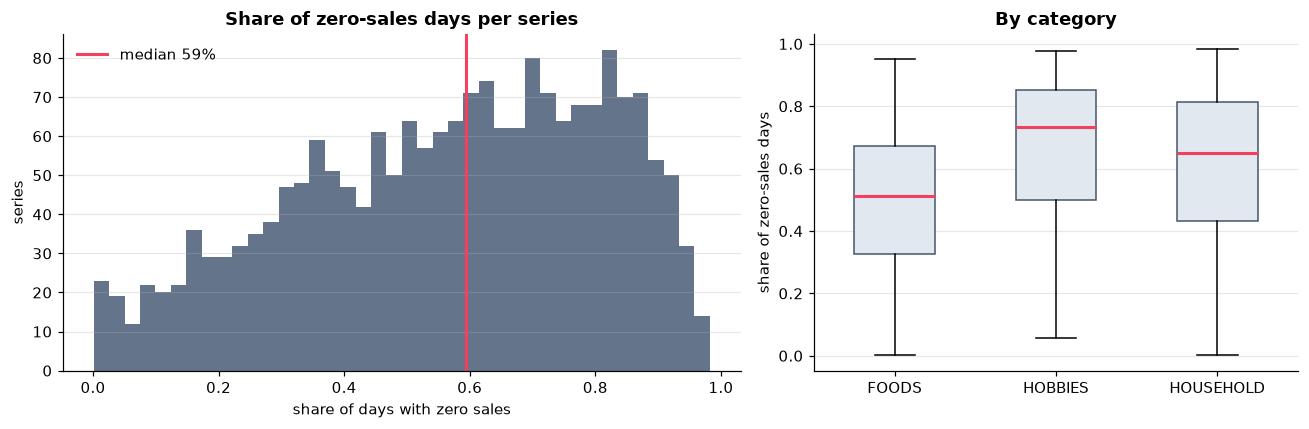

overall zero-sales share 56.3%; series selling nothing on more than half of days: 62%
{'FOODS': 0.51, 'HOBBIES': 0.73, 'HOUSEHOLD': 0.65}


In [5]:
zero = df.assign(zero=df["y"].eq(0)).groupby(["unique_id", "cat_id"])["zero"].mean().reset_index()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.4, 1]})
a1.hist(zero["zero"], bins=40, color="#64748b")
a1.axvline(zero["zero"].median(), color="#f43f5e", lw=2, label=f"median {zero['zero'].median():.0%}")
a1.set(title="Share of zero-sales days per series", xlabel="share of days with zero sales", ylabel="series")
a1.legend()
cats = sorted(zero["cat_id"].unique())
a2.boxplot([zero.loc[zero["cat_id"] == c, "zero"] for c in cats], tick_labels=cats, widths=0.5,
           medianprops={"color": "#f43f5e", "lw": 2}, patch_artist=True,
           boxprops={"facecolor": "#e2e8f0", "edgecolor": "#475569"})
a2.set(title="By category", ylabel="share of zero-sales days")
save(fig, "03_zero_sales_share")
plt.show()
print(f"overall zero-sales share {df['y'].eq(0).mean():.1%}; "
      f"series selling nothing on more than half of days: {(zero['zero'] > 0.5).mean():.0%}")
print(zero.groupby("cat_id")["zero"].median().round(2).to_dict())

**Reading.** Zero is the single most common daily value: over half of all series-days
have no sale, and the typical series sells nothing on most days (median printed above).
FOODS items sell more regularly than HOBBIES and HOUSEHOLD.

**Implication.** Squared-error losses and Gaussian assumptions fit poorly. We train
LightGBM with a **Tweedie** loss (zero-inflated, right-skewed counts), add Croston/TSB as
intermittent-demand baselines, and use scale-free metrics (RMSSE) so slow movers count.

## 4 · Demand classification (Syntetos–Boylan ADI / CV²)

* **ADI** — average inter-demand interval = days ÷ days with a sale (1 = sells daily).
* **CV²** — squared coefficient of variation of the *non-zero* quantities (size variability).

Thresholds ADI = 1.32 and CV² = 0.49 split series into four classes:

| | CV² < 0.49 (stable sizes) | CV² ≥ 0.49 (variable sizes) |
|---|---|---|
| **ADI < 1.32** (frequent) | smooth | erratic |
| **ADI ≥ 1.32** (infrequent) | intermittent | lumpy |

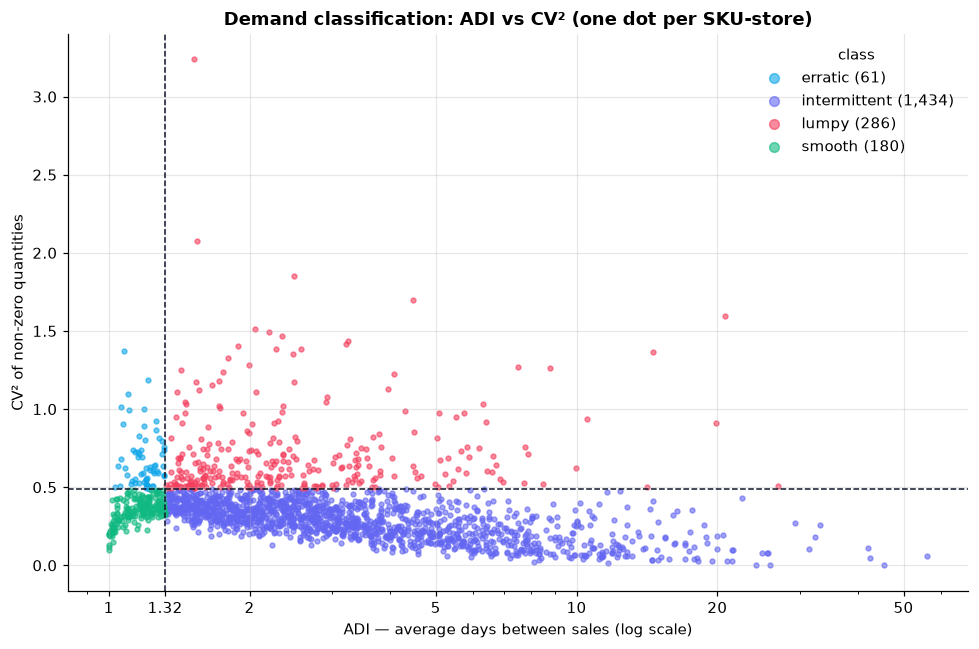

class      erratic  intermittent  lumpy  smooth   All
cat_id                                               
FOODS           36           581    191     109   917
HOBBIES         17           292     55       6   370
HOUSEHOLD        8           561     40      65   674
All             61          1434    286     180  1961
{'intermittent': 73.1, 'lumpy': 14.6, 'smooth': 9.2, 'erratic': 3.1}


In [6]:
prof = df.groupby(["unique_id", "cat_id"])["y"].agg(lambda s: demand_profile(s.to_numpy(dtype=float)))
prof = pd.DataFrame(prof.tolist(), index=prof.index, columns=["adi", "cv2"]).reset_index()
prof["class"] = [classify_profile(a, c) for a, c in zip(prof["adi"], prof["cv2"])]
prof = prof[np.isfinite(prof["adi"])]

fig, ax = plt.subplots(figsize=(9, 6))
for cls, g in prof.groupby("class"):
    ax.scatter(g["adi"], g["cv2"], s=10, alpha=0.6, color=CLASS_COLORS[cls], label=f"{cls} ({len(g):,})")
ax.axvline(ADI_CUT, color="#0f172a", lw=1, ls="--")
ax.axhline(CV2_CUT, color="#0f172a", lw=1, ls="--")
ax.set(xscale="log", title="Demand classification: ADI vs CV² (one dot per SKU-store)",
       xlabel="ADI — average days between sales (log scale)", ylabel="CV² of non-zero quantities")
ax.set_xticks([1, ADI_CUT, 2, 5, 10, 20, 50])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.grid(True, axis="both", alpha=0.3)
ax.legend(title="class", loc="upper right", markerscale=2)
save(fig, "04_demand_classification")
plt.show()
counts = pd.crosstab(prof["cat_id"], prof["class"], margins=True)
print(counts.to_string())
print((prof["class"].value_counts(normalize=True) * 100).round(1).to_dict())

**Reading.** The large majority of series are **intermittent** (infrequent sales of
fairly stable size); lumpy series (infrequent *and* variable) form the next group, while
smooth and erratic series — the ones classical methods are built for — are a minority
(shares printed above).

**Implication.** The model set must handle intermittency (Croston, TSB, Tweedie LightGBM),
and inventory buffers should come from measured forecast errors rather than a normal
daily-demand assumption.

## 5 · Weekly seasonality

Average demand on each weekday relative to the series' overall mean (1.0 = an average
day), per category.

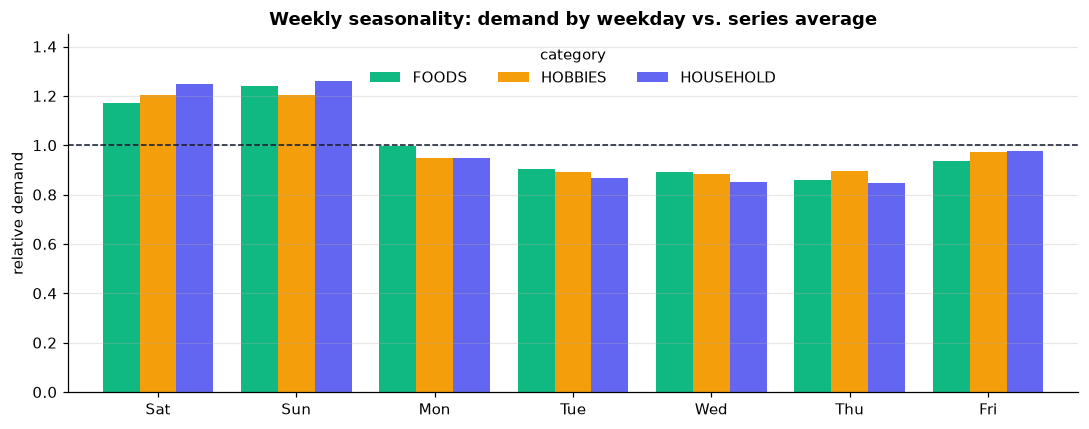

weekend (Sat+Sun) vs weekdays (Mon–Fri): 1.34x
wday        Sat   Sun   Mon   Tue   Wed   Thu   Fri
cat_id                                             
FOODS      1.17  1.24  1.00  0.90  0.89  0.86  0.94
HOBBIES    1.20  1.21  0.95  0.89  0.88  0.89  0.97
HOUSEHOLD  1.25  1.26  0.95  0.87  0.85  0.85  0.98


In [7]:
weekly = df.groupby(["cat_id", "wday"])["rel"].mean().unstack(0).rename(index=WEEKDAYS)
fig, ax = plt.subplots()
weekly.plot.bar(ax=ax, color=[COLORS[c] for c in weekly.columns], width=0.8, rot=0)
ax.axhline(1.0, color="#0f172a", lw=1, ls="--")
ax.set(title="Weekly seasonality: demand by weekday vs. series average", xlabel="", ylabel="relative demand",
       ylim=(0, 1.45))
ax.grid(False, axis="x")
ax.legend(title="category", ncol=3, loc="upper center")
save(fig, "05_weekly_seasonality")
plt.show()

w = df.groupby("wday")["rel"].mean()
print(f"weekend (Sat+Sun) vs weekdays (Mon–Fri): {w[[1, 2]].mean() / w[[3, 4, 5, 6, 7]].mean():.2f}x")
print(weekly.round(2).T.to_string())

**Reading.** Saturday and Sunday are the strongest days in every category and
mid-week (Tuesday–Thursday) the weakest; the weekend premium is printed above.

**Implication.** Weekday must be a feature; seasonal-naive and ETS(A,N,A) with a 7-day
season are the right statistical baselines; and a reorder point should follow the
*daily* forecast rather than a flat average.

## 6 · Yearly seasonality

Left: mean relative demand by calendar month. Right: weekly totals for each year
overlaid by week of the year (each year divided by its own mean, so the level drift of
§1 does not hide the seasonal shape).

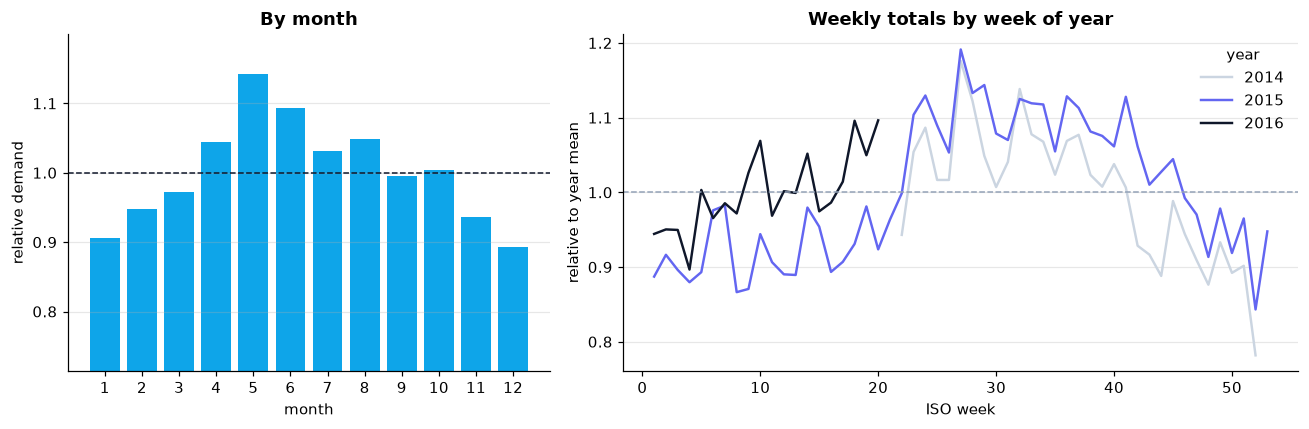

relative demand by month: {1: 0.907, 2: 0.947, 3: 0.972, 4: 1.045, 5: 1.143, 6: 1.094, 7: 1.031, 8: 1.049, 9: 0.995, 10: 1.004, 11: 0.937, 12: 0.893}


In [8]:
monthly_idx = df.groupby("month")["rel"].mean()
weekly_tot = df.set_index("ds")["y"].resample("W-SAT").sum().iloc[1:-1]  # full weeks only
iso = weekly_tot.index.isocalendar()  # ISO year, so early-January weeks stay with their year
by_year = pd.DataFrame({"y": weekly_tot.to_numpy(), "year": iso.year.to_numpy(), "week": iso.week.to_numpy()})
by_year = by_year.sort_values(["year", "week"])
by_year["idx"] = by_year["y"] / by_year.groupby("year")["y"].transform("mean")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 1.4]})
a1.bar(monthly_idx.index, monthly_idx, color="#0ea5e9")
a1.axhline(1.0, color="#0f172a", lw=1, ls="--")
a1.set(title="By month", xticks=range(1, 13), xlabel="month", ylabel="relative demand",
       ylim=(0.8 * monthly_idx.min(), 1.05 * monthly_idx.max()))
for (year, g), color in zip(by_year.groupby("year"), ["#cbd5e1", "#6366f1", "#0f172a"]):
    a2.plot(g["week"], g["idx"], lw=1.6, color=color, label=str(year))
a2.axhline(1.0, color="#94a3b8", lw=1, ls="--")
a2.set(title="Weekly totals by week of year", xlabel="ISO week", ylabel="relative to year mean")
a2.legend(title="year")
save(fig, "06_yearly_seasonality")
plt.show()
print("relative demand by month:", monthly_idx.round(3).to_dict())

**Reading.** There is a clear annual cycle: demand runs above average from April to August
(peaking in May, about +14 %) and below average from November to February (lowest in
December, about −11 %; values printed above). The week-of-year curves of 2014 and 2015
follow the same shape. The swing is a little smaller than the weekly one (§5), and with
only two years of data its shape is estimated from two cycles.

**Implication.** The annual component is captured by month / week-of-year features and a
364-day lag; no separate yearly seasonal model is needed, but a flat yearly average would
misjudge summer and winter demand.

## 7 · Price vs sales — elasticity hints

Left: demand relative to the item's same-weekday average, grouped by how far the price is
from the item's usual (median) price; bar labels give the share of rows in each bin.
Right: a price-elasticity *hint* — weekly units against weekly price within each item,
after removing each item's own average and each week's common level (two-way fixed
effects, so overall growth and inflation cannot masquerade as a price effect). Only weeks
within ±15 % of the usual price are used, so clearance pricing does not dominate.

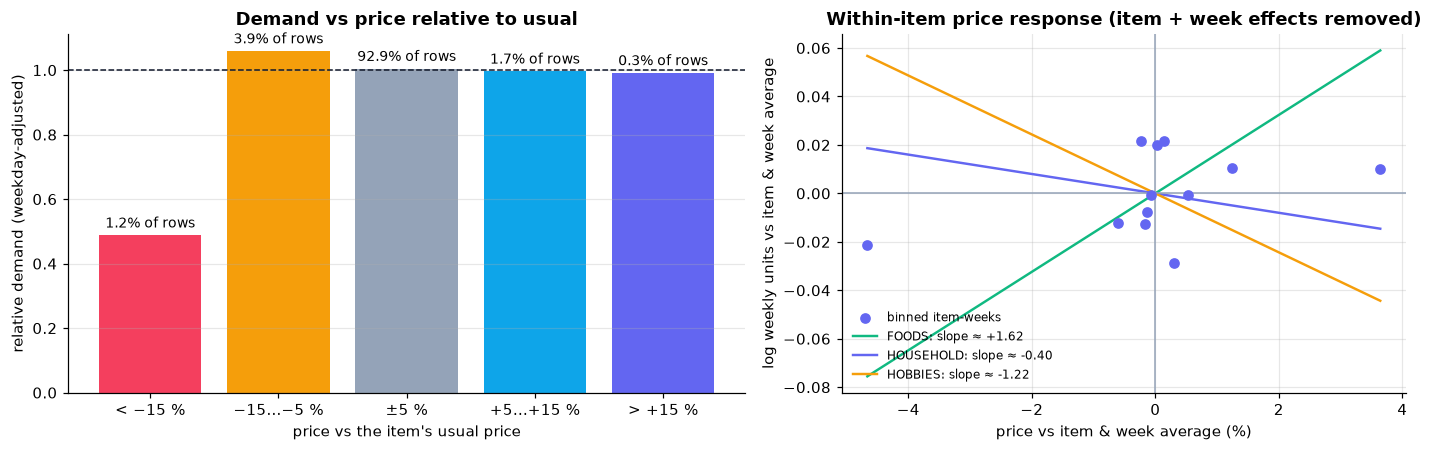

             rel  share
price_rel              
< −15 %    0.488  0.012
−15…−5 %   1.059  0.039
±5 %       1.004  0.929
+5…+15 %   0.996  0.017
> +15 %    0.991  0.003
price changes per item over the period (median): {'FOODS': 1.0, 'HOBBIES': 0.0, 'HOUSEHOLD': 0.0}
items with no price change at all: 51%
weekly observations: 194,217
two-way FE elasticity estimates: {'all': 0.81, 'FOODS': 1.62, 'HOBBIES': -1.22, 'HOUSEHOLD': -0.4}


In [9]:
df["price_rel"] = df["sell_price"] / df.groupby("unique_id")["sell_price"].transform("median")
edges = [0, 0.85, 0.95, 1.05, 1.15, np.inf]
labels = ["< −15 %", "−15…−5 %", "±5 %", "+5…+15 %", "> +15 %"]
bins = pd.cut(df["price_rel"], edges, labels=labels, right=False)
price = df.groupby(bins, observed=True).agg(rel=("rel_dow", "mean"), share=("rel_dow", "size"))
price["share"] = price["share"] / price["share"].sum()

# Weekly panel at ordinary price levels (±15 % of the item's usual price).
wk = (df.assign(week=df["ds"].dt.to_period("W"))
        .groupby(["unique_id", "cat_id", "week"])
        .agg(units=("y", "sum"), price=("sell_price", "mean"))
        .reset_index())
wk["rel"] = wk["price"] / wk.groupby("unique_id")["price"].transform("median")
wk = wk[wk["rel"].between(0.85, 1.15)].copy()
wk["lq"], wk["lp"] = np.log1p(wk["units"]), np.log(wk["price"])


def two_way_demean(x: pd.DataFrame, col: str, iters: int = 30) -> pd.Series:
    """Remove item and week means (alternating projections = two-way fixed effects)."""
    v = x[col].copy()
    for _ in range(iters):
        v = v - v.groupby(x["unique_id"]).transform("mean")
        v = v - v.groupby(x["week"]).transform("mean")
    return v


def elasticity(x: pd.DataFrame) -> float:
    dq, dp = two_way_demean(x, "lq"), two_way_demean(x, "lp")
    return float((dq * dp).sum() / (dp**2).sum())


wk["dq"], wk["dp"] = two_way_demean(wk, "lq"), two_way_demean(wk, "lp")
elast = {"all": elasticity(wk)} | {c: elasticity(g) for c, g in wk.groupby("cat_id")}
changes = (df.sort_values(["unique_id", "ds"]).groupby("unique_id")["sell_price"]
             .apply(lambda p: int((p.diff().abs() > 0.005).sum())))
cat_of = df.groupby("unique_id")["cat_id"].first()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.2, 1]})
bars = a1.bar(price.index.astype(str), price["rel"], color=["#f43f5e", "#f59e0b", "#94a3b8", "#0ea5e9", "#6366f1"])
for bar, share in zip(bars, price["share"]):
    a1.annotate(f"{share:.1%} of rows", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom", fontsize=9, xytext=(0, 3), textcoords="offset points")
a1.axhline(1.0, color="#0f172a", lw=1, ls="--")
a1.set(title="Demand vs price relative to usual", xlabel="price vs the item's usual price",
       ylabel="relative demand (weekday-adjusted)")
binned = wk.groupby(pd.qcut(wk["dp"], 12, duplicates="drop"), observed=True)[["dp", "dq"]].mean()
a2.scatter(binned["dp"] * 100, binned["dq"], color="#6366f1", s=36, zorder=3, label="binned item-weeks")
xs = np.linspace(binned["dp"].min(), binned["dp"].max(), 2)
for cat, color in COLORS.items():
    a2.plot(xs * 100, elast[cat] * xs, color=color, lw=1.6, label=f"{cat}: slope ≈ {elast[cat]:+.2f}")
a2.axhline(0, color="#94a3b8", lw=1)
a2.axvline(0, color="#94a3b8", lw=1)
a2.set(title="Within-item price response (item + week effects removed)",
       xlabel="price vs item & week average (%)", ylabel="log weekly units vs item & week average")
a2.grid(True, axis="both", alpha=0.3)
a2.legend(loc="lower left", fontsize=8)
save(fig, "07_price_vs_sales")
plt.show()

print(price.round(3).to_string())
print("price changes per item over the period (median):", changes.groupby(cat_of).median().to_dict())
print("items with no price change at all:", f"{(changes == 0).mean():.0%}")
print(f"weekly observations: {len(wk):,}")
print("two-way FE elasticity estimates:", {k: round(v, 2) for k, v in elast.items()})

**Reading.** Prices are almost always at the item's usual level (93 % of rows within
±5 %) and rarely change: half of all items keep a single price for the whole two years,
and the median item changes price at most once. Moderate discounts coincide with ≈ 6 %
more demand, while deep reductions (more than 15 % below usual, 1.2 % of rows) coincide
with about half the normal demand — clearance rather than promotions.

The within-item estimate (right) shows why a price elasticity cannot be measured reliably
from this data: the binned points scatter without a clear pattern, and the category slopes
even disagree in sign — HOBBIES (≈ −1.2) and HOUSEHOLD (≈ −0.4) have the expected negative
sign, FOODS (≈ +1.6) does not (values printed above). With so little price variation these
are *hints*, not causal elasticities; price changes are confounded with other changes to
the item (assortment, placement, life cycle).

**Implication.** Price enters the model only as relative-price features (`price_norm`,
`price_change_7`), so LightGBM can use it where it is informative without an imposed
elasticity. The inventory policies do not depend on a price response.

## 8 · Event and SNAP effects

Weekday-adjusted relative demand (1.0 = a normal day for that weekday). SNAP days are
the dates on which US food-stamp benefits are paid out; in California they are the first
ten days of every month.

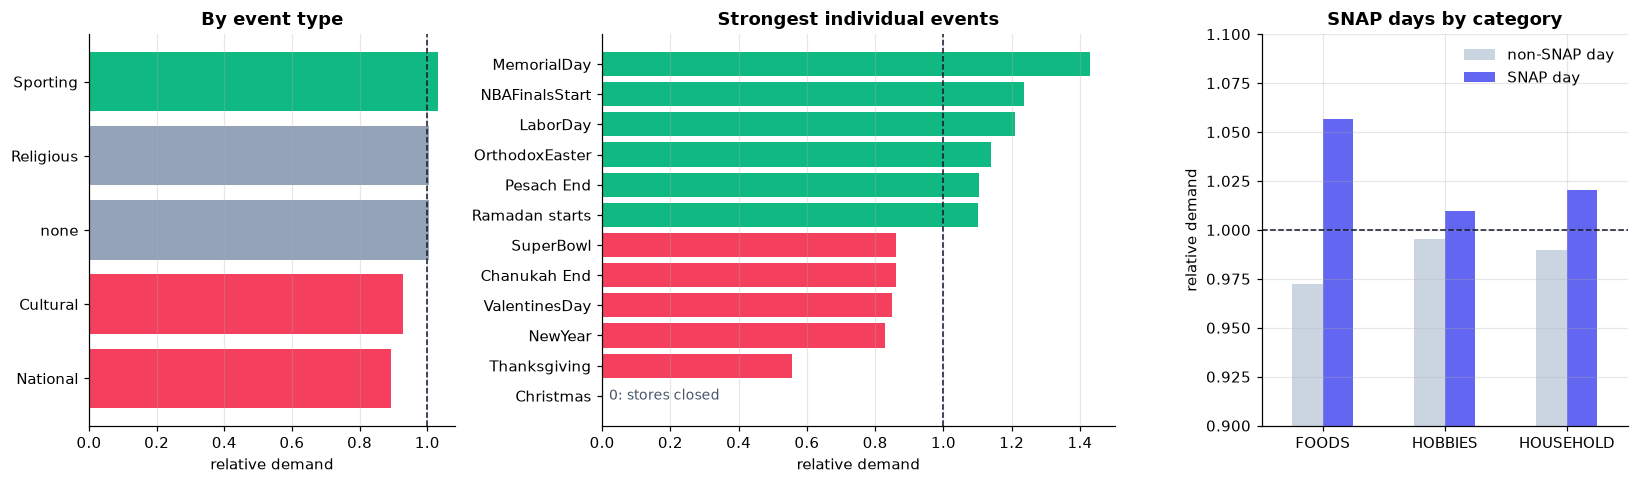

{'National': 0.894, 'Cultural': 0.927, 'none': 1.004, 'Religious': 1.004, 'Sporting': 1.031}
lowest: {'Christmas': 0.0, 'Thanksgiving': 0.56, 'NewYear': 0.83, 'ValentinesDay': 0.85}
highest: {'OrthodoxEaster': 1.14, 'LaborDay': 1.21, 'NBAFinalsStart': 1.24, 'MemorialDay': 1.43}
{'FOODS': 8.7, 'HOBBIES': 1.5, 'HOUSEHOLD': 3.1}


In [10]:
event_type = df.groupby("event_type_1")["rel_dow"].mean().sort_values()
events = df[df["event_type_1"] != "none"].groupby("event_name_1")["rel_dow"].mean().sort_values()
snap = df.groupby(["cat_id", "snap"])["rel_dow"].mean().unstack()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1, 1.4, 1]})
def tone(v: float) -> str:
    return "#94a3b8" if abs(v - 1) < 0.02 else ("#f43f5e" if v < 1 else "#10b981")


axes[0].barh(event_type.index, event_type, color=[tone(v) for v in event_type])
axes[0].axvline(1.0, color="#0f172a", lw=1, ls="--")
axes[0].set(title="By event type", xlabel="relative demand")
extremes = pd.concat([events.head(6), events.tail(6)])
axes[1].barh(extremes.index, extremes, color=[tone(v) for v in extremes])
for name, v in extremes.items():
    if v < 0.05:
        axes[1].annotate("0: stores closed", (0.02, name), va="center", fontsize=9, color="#475569")
axes[1].axvline(1.0, color="#0f172a", lw=1, ls="--")
axes[1].set(title="Strongest individual events", xlabel="relative demand")
snap.rename(columns={0: "non-SNAP day", 1: "SNAP day"}).plot.bar(ax=axes[2], color=["#cbd5e1", "#6366f1"], rot=0)
axes[2].axhline(1.0, color="#0f172a", lw=1, ls="--")
axes[2].set(title="SNAP days by category", xlabel="", ylabel="relative demand", ylim=(0.9, 1.1))
axes[2].legend(loc="upper right")
for ax in axes[:2]:
    ax.grid(True, axis="x", alpha=0.3)
    ax.grid(False, axis="y")
save(fig, "08_event_effects")
plt.show()
print(event_type.round(3).to_dict())
print("lowest:", events.head(4).round(2).to_dict())
print("highest:", events.tail(4).round(2).to_dict())
print((snap[1] / snap[0] - 1).mul(100).round(1).rename("SNAP uplift %").to_dict())

**Reading.** By type, national holidays lower demand most (≈ −11 %) and cultural events
also lower it (≈ −7 %); sporting events raise it slightly and religious events are
neutral. Individual events matter more than their type: Christmas (closed) and
Thanksgiving (≈ −44 %) fall sharply, while Memorial Day (≈ +43 %), the NBA Finals start
and Labor Day rise. SNAP days lift FOODS sales by ≈ 9 %, non-food categories only 1–3 %
(all values printed above).

**Implication.** Event type, event and SNAP indicators are known in advance for any
future date, so they are leakage-free features; their effects are category-specific,
which a global tree model with category features captures naturally.

## 9 · Store and category comparison

Left: average units sold per day in each store, split by category. Right: share of
zero-sales days per store and category (how intermittent each store's assortment is).

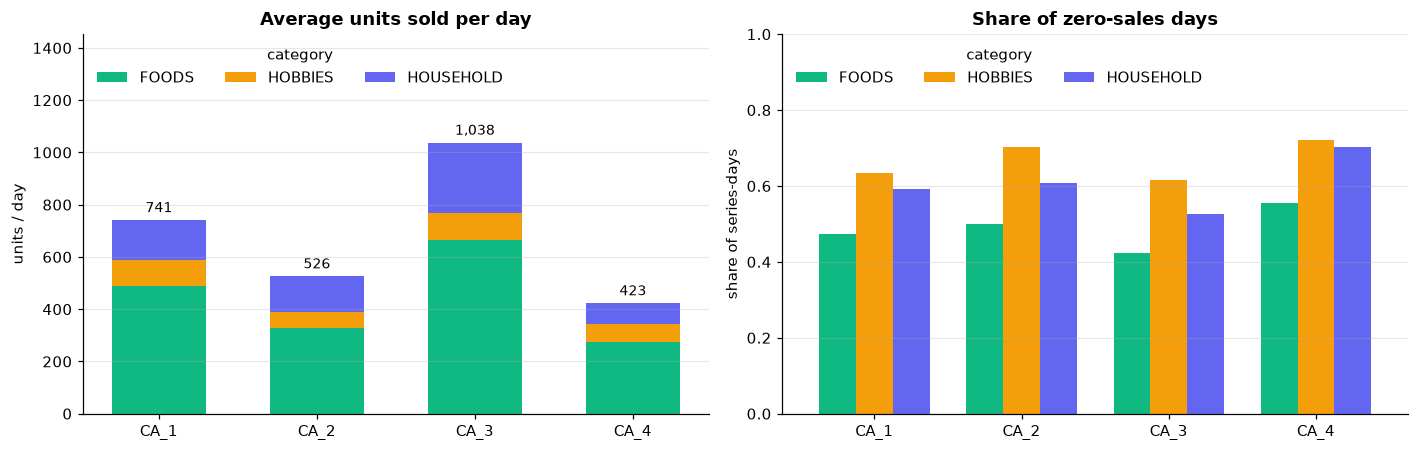

units/day by store and category:
cat_id    FOODS  HOBBIES  HOUSEHOLD
store_id                           
CA_1      488.0    100.0      154.0
CA_2      327.0     62.0      136.0
CA_3      666.0    101.0      271.0
CA_4      276.0     68.0       80.0
store share of all units: {'CA_1': 0.272, 'CA_2': 0.193, 'CA_3': 0.38, 'CA_4': 0.155}
zero-sales share:
cat_id    FOODS  HOBBIES  HOUSEHOLD
store_id                           
CA_1      0.474    0.633      0.591
CA_2      0.499    0.702      0.607
CA_3      0.423    0.615      0.526
CA_4      0.556    0.720      0.702


In [11]:
store_cat = df.groupby(["store_id", "cat_id", "ds"])["y"].sum().groupby(["store_id", "cat_id"]).mean().unstack()
zero_sc = df.assign(zero=df["y"].eq(0)).groupby(["store_id", "cat_id"])["zero"].mean().unstack()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.2))
bottom = np.zeros(len(store_cat))
for cat in store_cat.columns:
    a1.bar(store_cat.index, store_cat[cat], bottom=bottom, color=COLORS[cat], label=cat, width=0.6)
    bottom += store_cat[cat].to_numpy()
for x, total in zip(store_cat.index, bottom):
    a1.annotate(f"{total:,.0f}", (x, total), ha="center", va="bottom", fontsize=9, xytext=(0, 3), textcoords="offset points")
a1.set(title="Average units sold per day", ylabel="units / day", ylim=(0, bottom.max() * 1.4))
a1.legend(title="category", ncol=3, loc="upper left")
zero_sc.plot.bar(ax=a2, color=[COLORS[c] for c in zero_sc.columns], rot=0, width=0.75)
a2.set(title="Share of zero-sales days", xlabel="", ylabel="share of series-days", ylim=(0, 1))
a2.legend(title="category", ncol=3, loc="upper left")
for ax in (a1, a2):
    ax.grid(False, axis="x")
save(fig, "09_store_category")
plt.show()

print("units/day by store and category:"); print(store_cat.round(0).to_string())
print("store share of all units:", (store_cat.sum(axis=1) / store_cat.to_numpy().sum()).round(3).to_dict())
print("zero-sales share:"); print(zero_sc.round(3).to_string())

**Reading.** Stores differ mainly in size: CA_3 is the largest (≈ 1,040 units/day, 38 % of
all units) and CA_4 the smallest (≈ 420 units/day, 16 %). FOODS is 62–66 % of every store's
volume. Intermittency follows store size — CA_4's assortment has the most zero-sales days
(56–72 % by category), CA_3's the fewest (42–62 %) — and in every store HOBBIES is the most
intermittent category (values printed above).

**Implication.** Store and category carry real level information, so `store_id` and
`cat_id` are model features; one global LightGBM model learns these level differences
while sharing common patterns (the weekly cycle, events) across all stores.

## Summary — what the data tells the modelling

| Finding | Consequence in the engine |
|---|---|
| Strong weekly cycle; clear summer-high / winter-low yearly cycle | weekday, month and week-of-year features, 364-day lag, 7-day seasonal baselines, daily (not flat) reorder points |
| Small, skewed daily counts; top 20 % of series sell 65 % of units | Tweedie loss; revenue-weighted WRMSSE as headline metric |
| Over half of all series-days are zero; most series intermittent | Tweedie LightGBM, Croston / TSB baselines, RMSSE-based evaluation |
| Prices rarely change (half of items never); price response non-monotone and not reliably identifiable | relative-price features only; no elasticity assumed in the inventory policies |
| Event effects differ by event (Thanksgiving −44 %, Memorial Day +43 %); SNAP lifts FOODS | event and SNAP features (known in advance) |
| Stores differ mainly in size (CA_3 ≈ 2.5× CA_4); HOBBIES most intermittent everywhere | store and category features in one global model |
| Demand grows ≈ 10 % a year (≈ 5 % like-for-like, rest from newly selling items) | recent-demand ("origin") features; bias correction in safety stock |

Figures for the report: `docs/figures/01_*.png` … `09_*.png`.